# KQC Simple — one Swissmon capacitively coupled to a through line (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' minimal connected chip, `chips/simple.py` (class `Simple`, default parameters,
chip name "Simple"; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`third_party/KQCircuits/klayout_package/python/kqcircuits/chips/simple.py`; spec `docs/designs/kqc/test_chips.md`,
row *Simple*: "the smoke test for KQC parity"). Three SMA8 launchers (WN, EN, SE); a Swissmon whose flux line
comes straight from WN; its coupler 1 feeds a finger capacitor C1 into a T; the T's right arm goes to EN, its
bottom arm through a second finger capacitor C2 to SE.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (the SMA8 launchers sit on its edges), Quantcore die frame, device ID "Simple" |
| launchers | SMA8 (WN, EN, SE enabled), `launcher_indent` 800 µm (outer etch 20 µm from the edge) | same three, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junction | KQC Manhattan SQUID (assumed L_J 12 nH) | Quantcore trilayer SQUID, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept exactly |
| placement | everything on the WN–EN line (y = 7200) and the SE column (x = 7200) | **kept off-centre on purpose** (content centre 879 µm below the die centre, see Design 8): the three fixed launcher ports set the content box, so no shift of the inner parts can centre it |

**Kept exactly (same KQC cells, parameters and positions):** the SMA8 launchers with only WN, EN, SE enabled;
the `Swissmon` (`cpl_length=[0, 150, 0]`) rotated 270° at (2500, 7200); C1 and C2,
`FingerCapacitorSquare(finger_width=20, finger_length=100, finger_number=7)` at (5000, 7200) and, rotated 270°,
at (7200, 5000); the `WaveguideCoplanarSplitter` T (lengths 11/11/11 µm) at (7200, 7200); the six straight CPWs
WN → flux, cplr1 → C1, C1 → T, T → EN, T → C2, C2 → SE.

**Simplified:** nothing in the geometry; KQC's `Simple` has no junction-test arrays or other extras.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its three SMA8 launchers, the launchers and the pad rule, the signal line (C1, the T, C2 and their four straight routes), the Swissmon, its coupler route to C1, the flux line, and then the whole chip (the sim group, the placement, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `simple.v1.ipynb`; both save the same `simple.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/simple/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/simple")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die and its launchers, the line the signal runs on,
the qubit, what joins the qubit to the line, the control line, and then the whole chip. Each segment is one cell with
one picture of the chip so far (live, KLayout redraws after every cell). A route joins two ports, so the line between
the capacitors and the launchers can be drawn before the qubit, and the qubit's own routes come after it. KQC's ground grid (`with_grid`, ≈ 0.8 M holes) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and the SMA8 sample holder's WN, EN, SE launchers |
| 2 | the launchers and the pad rule (they come with the die: a look and a table) |
| 3 | the signal line: C1, the T, C2 and the four straight CPWs C1 → T → EN, T → C2 → SE |
| 4 | the qubit: the Swissmon with its trilayer SQUID |
| 5 | the readout: no resonator here; the straight `W1` from the qubit's coupler 1 onto C1 |
| 6 | the coupling: none (one qubit) |
| 7 | the control routing: the flux line `FLUX` from WN |
| 8 | the whole chip: the sim group, the placement (kept off-centre), save |

## Design 1 · The die, its frame and the launchers

`Designer(...)` starts the chip: the 10 × 10 mm box, the SMA8 sample holder with only WN, EN and SE enabled, and
the chip name "Simple", which the Quantcore frame writes as the device ID on a free edge. `with_grid=True` asks
for KQC's whole-area ground grid (the original's cheese); the PDK band is then not added (chip `cheese` stays
`"auto"`). The frame is the PDK default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary
100/0); KQC's own `ChipFrame` is not drawn.

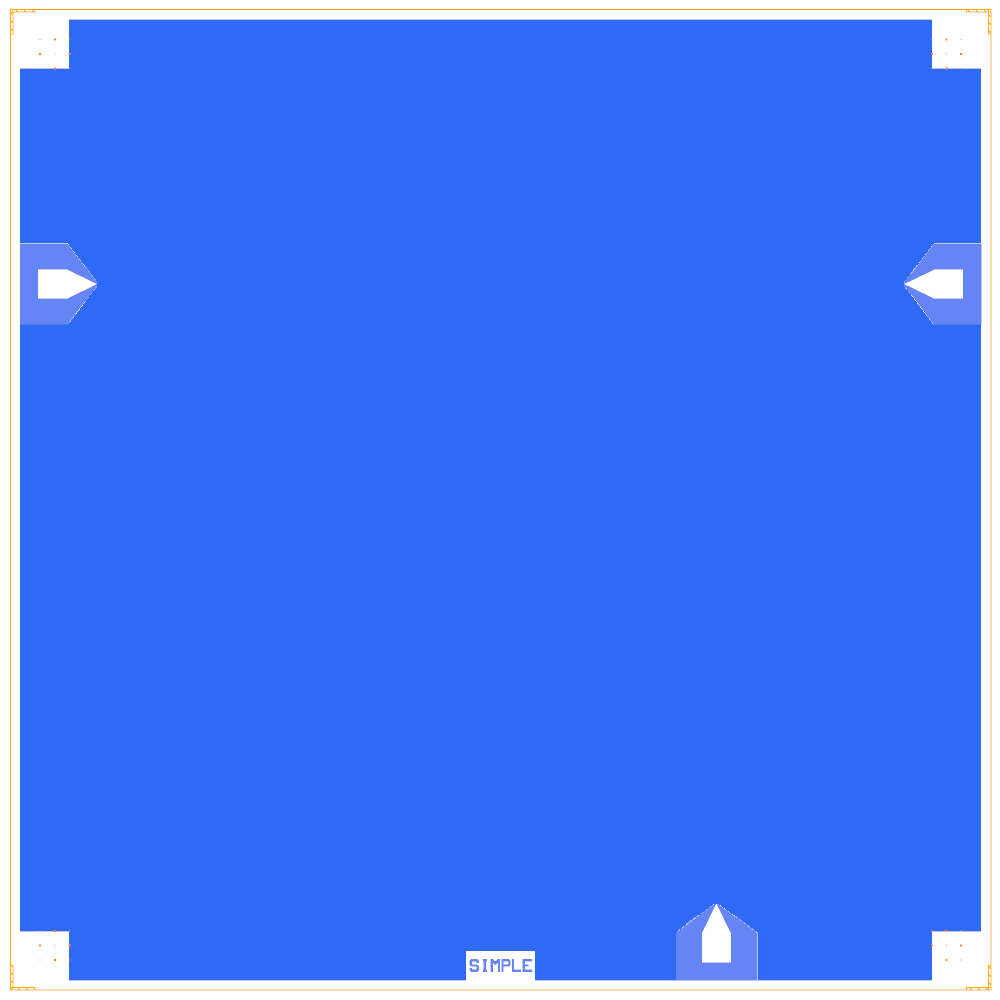

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/simple/1_die.png')

In [5]:
d = Designer("simple", box=(0, 0, 10000, 10000), launchers={"type": "SMA8", "enabled": ["WN", "EN", "SE"]},
             chip={"name_chip": "Simple", "with_grid": True}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the "
                 "pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For SMA8 (RF
launcher: 300 µm taper + 300 µm pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 +
180 = **880 µm** (KQC: 800 µm). The routes below start at the launcher ports, so the 80 µm shift needs no other
change. (Stand-alone pads take `edge="auto"` in `d.add`; this chip has none.)

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on WN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.EN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.SE | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.WN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

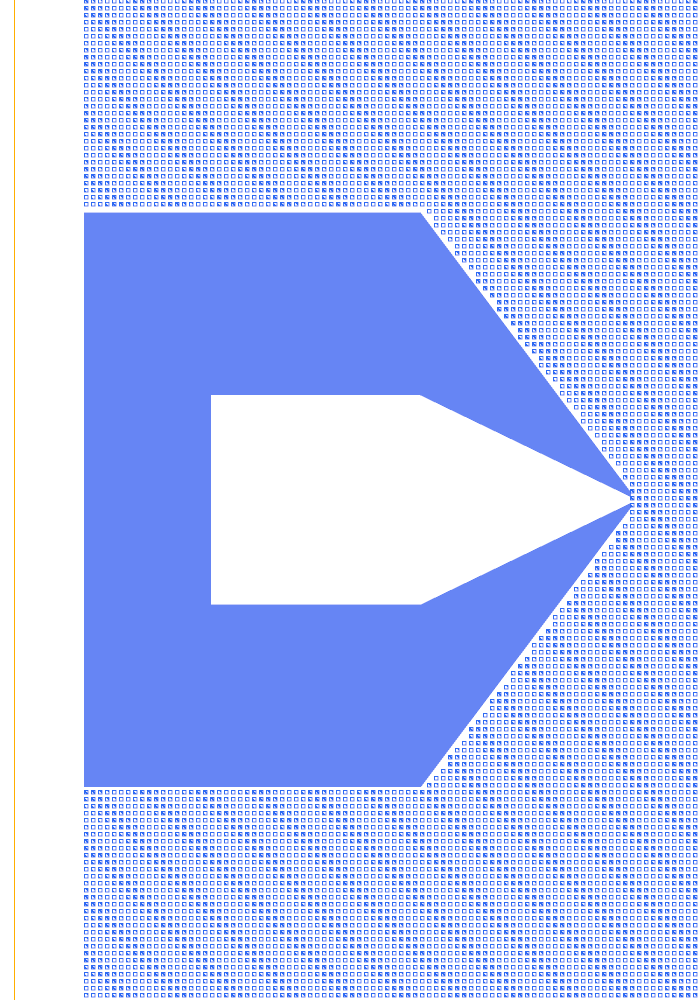

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.WN")
snap(d, STEPS / "2_launcher.png", box=(-20, y - 400, x + 100, y + 400), size=(700, 1000), width=300);

## Design 3 · Readout: the signal line

**Capacitors and the T.** C1 and C2 are the same `FingerCapacitorSquare` (7 fingers of 100 × 20 µm): C1 couples
the qubit's coupler to the line, C2 sits on the T's bottom arm towards SE. The `WaveguideCoplanarSplitter` T
(three 11 µm arms) splits the line at (7200, 7200).

Four straight CPWs (PDK default a = 10, b = 6 µm) join them: `W2` C1 → T, `W3` T → EN, `W4` T → C2, `W5` C2 → SE. None
of this needs the qubit, so it comes first. This chip has no readout resonator: KQC's smoke test couples the qubit
straight into this line through C1 (Design 5), which sets the qubit's decay into the two 50 Ω launchers.

<FingerCapacitorSquare C1 ports=['a', 'b']>
<WaveguideCoplanarSplitter T ports=['bottom', 'left', 'right']>


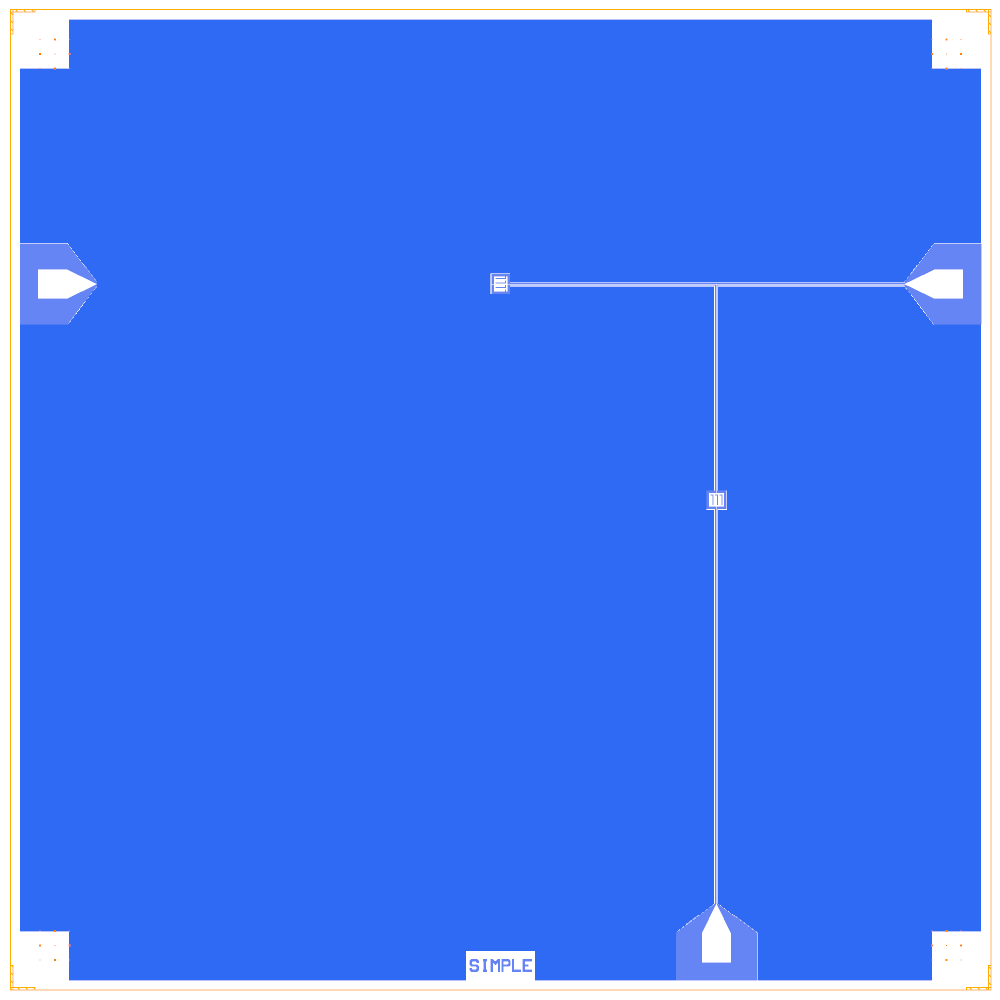

**On the chip so far:** 0 pads · 0 qubits · 3 other components · 4 routes · 0 declared couplings. **This step added** 3 component(s) `C1`, `C2`, `T` and 4 route(s) `W2`, `W3`, `W4`, `W5`.

WindowsPath('build/snapshots/simple/s3_signal_line.png')

In [7]:
with d.batch():
    cap = dict(finger_width=20, finger_length=100, finger_number=7)
    c1 = d.add("C1", "FingerCapacitorSquare", at=(5000, 7200), **cap)
    c2 = d.add("C2", "FingerCapacitorSquare", at=(7200, 5000), rot=270, **cap)
    t = d.add("T", "WaveguideCoplanarSplitter", at=(7200, 7200), lengths=[11, 11, 11],
              port_names=["right", "left", "bottom"])
    d.route("W2", c1.b, t.left)
    d.route("W3", t.right, "chip.EN")
    d.route("W4", t.bottom, c2.a)
    d.route("W5", c2.b, "chip.SE")
print(c1, t, sep="\n")
layout_step(d, STEPS / "s3_signal_line.png", **CHIP)

## Design 4 · Qubit placement: the Swissmon

**The junction from the PDK rule.** KQC draws a SQUID in the Swissmon. `trilayer_junction` turns it into the
Quantcore trilayer SQUID: two junctions whose straight finger is KQC's `junction_width` (the bent finger stays at
the PDK 0.6 µm). With the nominal L_J (6.73 nH, the 0.5 × 0.6 µm junction at R_n 45 kΩ) as the SQUID's parallel
total, each junction is 0.25 × 0.6 µm. `JJ_PARAMS` go on the cell, `JUNCTION` (L_J, C_J) is what the LOM and the
FEM junction port use.

**The qubit.** A KQC `Swissmon` (cross-shaped island with three couplers and a flux line) rotated 270° at
(2500, 7200), with only coupler 1 drawn (`cpl_length=[0, 150, 0]`: 150 µm). Ports: `cplr0`–`cplr2`, `drive`,
`flux`. The SQUID at the end of one arm carries the trilayer junction parameters of the cell above.

The first picture is the chip so far, the second zooms on the qubit (no rebuild: the same build).

In [8]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


<Swissmon QB ports=['cplr0', 'cplr1', 'cplr2', 'drive', 'flux']>


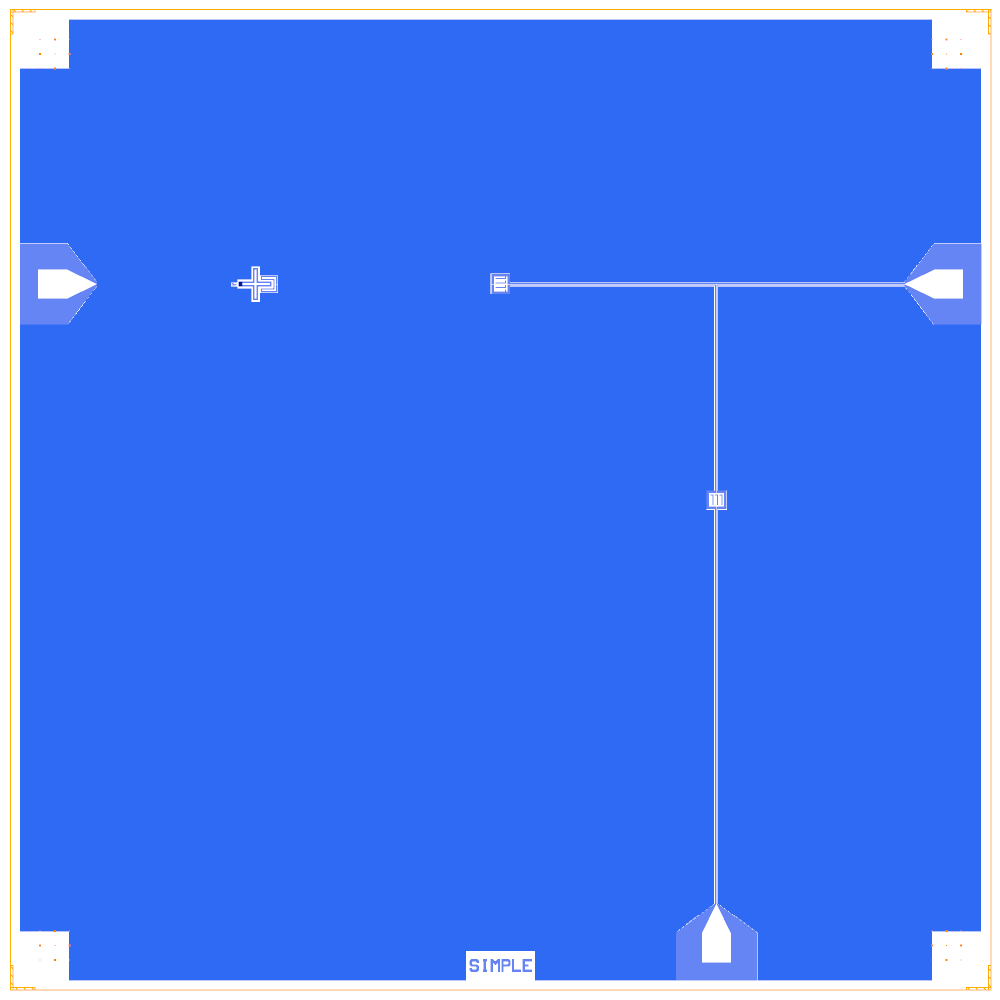

**On the chip so far:** 0 pads · 0 qubits · 4 other components · 4 routes · 0 declared couplings. **This step added** 1 component(s) `QB`. KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among the other components.

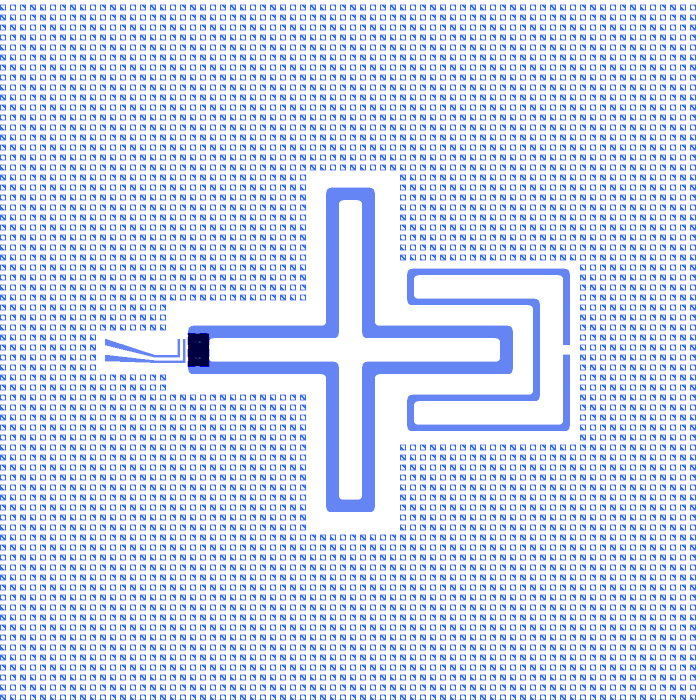

In [9]:
with d.batch():
    q = d.add("QB", "Swissmon", at=(2500, 7200), rot=270, cpl_length=[0, 150, 0], junction=JUNCTION, **JJ_PARAMS)
print(q)
layout_step(d, STEPS / "s4_qubit.png", **CHIP,
            note="KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among "
                 "the other components.")
snap(d, STEPS / "s4_qubit_zoom.png", box=(2150, 6850, 2850, 7550), size=(700, 700), width=300);

## Design 5 · Readout: the qubit onto the line

`W1`, a straight CPW from the qubit's coupler 1 to C1's port `a`. Through it and C1 the qubit sees the line, and the
two 50 Ω launchers at its ends: that is the qubit's decay rate κ (the Purcell-type T1 limit of this chip, LOM 1). Both
ends are ports, so the route follows the qubit and C1 wherever they are.

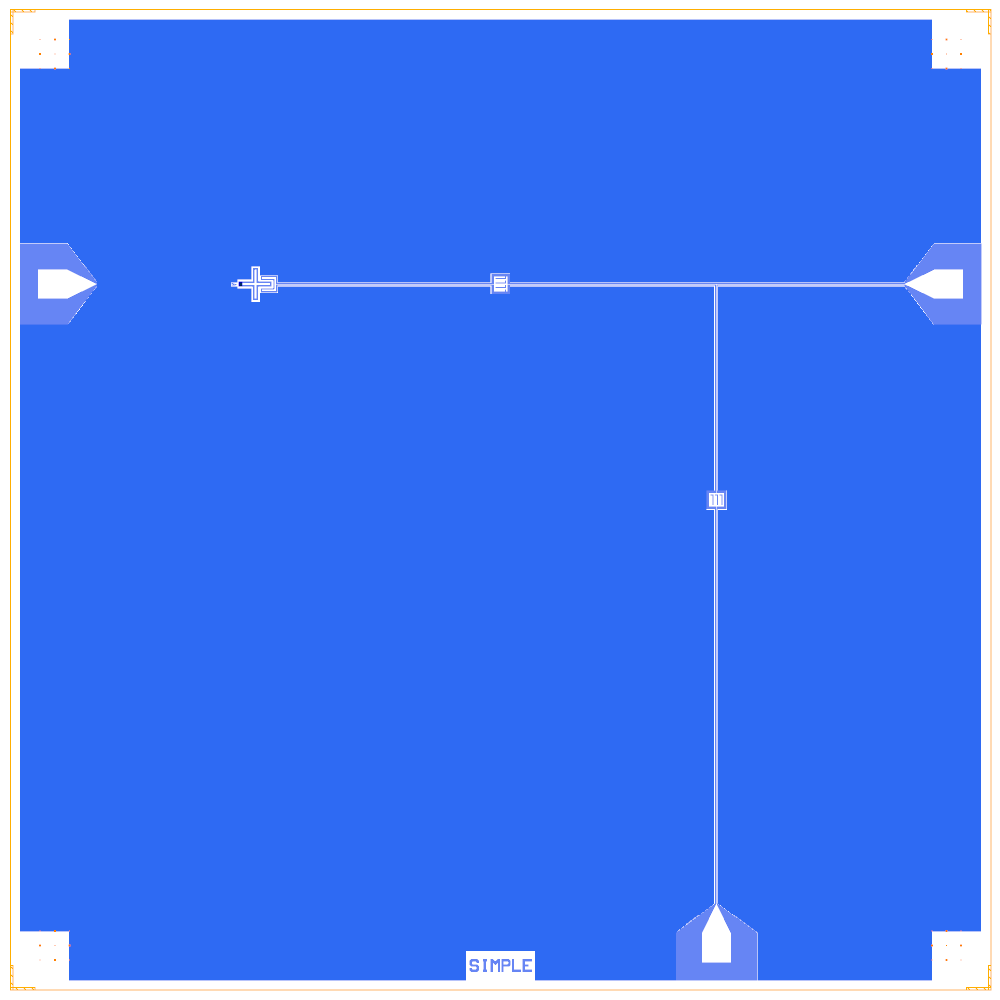

**On the chip so far:** 0 pads · 0 qubits · 4 other components · 5 routes · 0 declared couplings. **This step added** 1 route(s) `W1`.

WindowsPath('build/snapshots/simple/s5_coupler_route.png')

In [10]:
with d.batch():
    d.route("W1", q.cplr1, c1.a)
layout_step(d, STEPS / "s5_coupler_route.png", **CHIP)

## Design 6 · Coupling: none

One qubit, so there is no qubit–qubit coupling; its coupling to the line is C1 (Design 3) through `W1` (Design 5).

## Design 7 · Routing: the flux line

`FLUX`, straight from the WN launcher to the qubit's flux port (KQC's `Simple` has no charge line: the Swissmon's
`drive` port stays open, a DRC warning in Check 1).

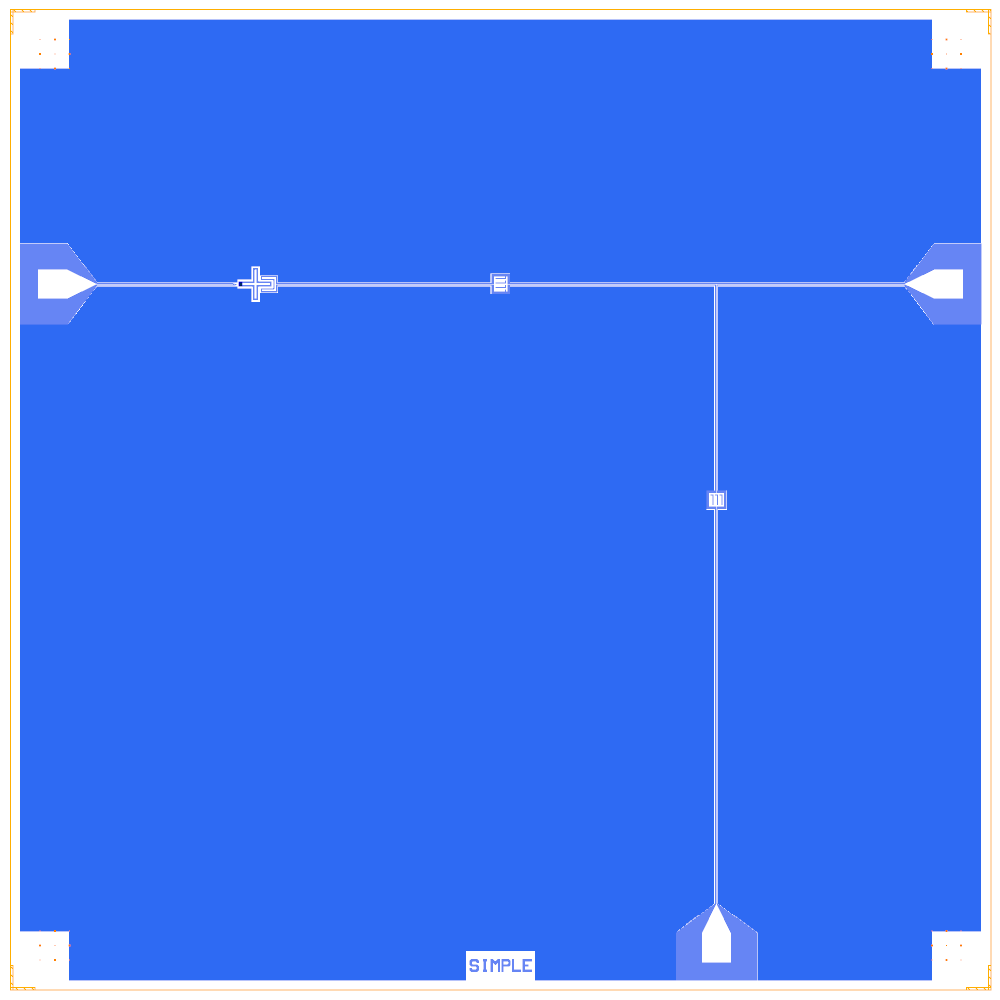

**On the chip so far:** 0 pads · 0 qubits · 4 other components · 6 routes · 0 declared couplings. **This step added** 1 route(s) `FLUX`.

WindowsPath('build/snapshots/simple/s7_flux.png')

In [11]:
with d.batch():
    d.route("FLUX", "chip.WN", q.flux)
layout_step(d, STEPS / "s7_flux.png", **CHIP)

## Design 8 · The whole chip: sim group, placement, save

**Sim group, placement, save.** One sim group: the qubit with C1 (Q3D C-matrix and eigenmode).

**Placement: kept off-centre on purpose.** The PDK asks for content centred in the die, but on this chip the
launchers set the content box. The qubit, C1 and the T sit on the straight line WN → EN (y = 7200) and C2 on the
straight T → SE (x = 7200), so the box runs from the SE launcher port (y = 880 µm) to the top of the WN–EN line
(y ≈ 7362 µm); in x it spans WN to EN and is centred. Its centre is ≈ 879 µm below the die centre. The
launchers belong to the SMA8 sample holder and do not move, so shifting the inner parts cannot centre the box:
`center_in_die` would lift the line by 879 µm, bend the WN → EN line at both ends, and still leave the box
≈ 440 µm low, because its bottom stays at the SE port. A centred box would need the line ≈ 1.76 mm above the
launchers it joins. So `center_in_die` is not applied; the offset is printed and reported in `pdk_report`
below. Then `simple.json` is saved with `save_design`, which compares it with the file it replaces (the previous
run's): the segments above changed how the chip is built (the line before the qubit), not the chip, so it should
say *same design*; the file keeps the previous key order, so `git diff` stays empty.

content centre − die centre: (+0, -879) µm (kept: the source is anchored to the fixed SMA8 launchers)


**Same design as before:** `examples/designs/kqc/simple.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer simple: 4 instances, 6 routes, live=False> → examples\designs\kqc\simple.json
{'W2': 2097.5, 'W3': 1909.0, 'W4': 2097.5, 'W5': 4028.5, 'W1': 2189.5, 'FLUX': 1374.67}


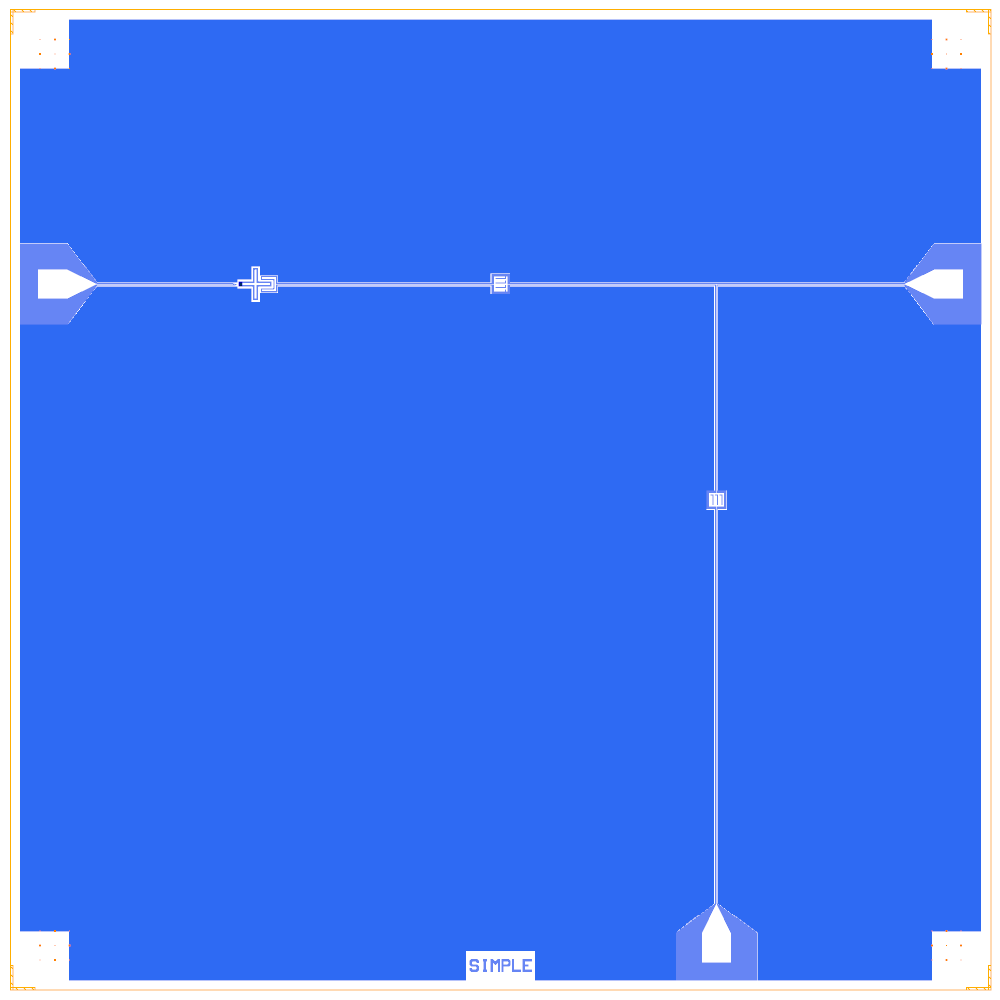

**On the chip so far:** 0 pads · 0 qubits · 4 other components · 6 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/simple/4_routes.png')

In [12]:
d.sim_group("QB_C1", ["QB", "C1"], analyses=["q3d_cmatrix", "eigenmode_epr"])
rebuild(d)
box = content_box(d)
print(f"content centre − die centre: ({box.center().x - 5000:+.0f}, {box.center().y - 5000:+.0f}) µm "
      "(kept: the source is anchored to the fixed SMA8 launchers)")
DESIGN, same = save_design(d, OUT / "simple.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})
layout_step(d, STEPS / "4_routes.png", **CHIP)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** the warnings are the Swissmon's zero-length couplers 0 and 2 (`cpl_length=[0, 150, 0]`; the LOM puts
their ports on ground) and its unused drive port (KQC's `Simple` has no charge line). No PDK design warning: the
`pdk_rn` check applies the 40–50 kΩ window to the device, i.e. the SQUID's parallel R_n (two 90 kΩ junctions =
45 kΩ, what a probe station measures across it).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit nodes,
routes join nodes, launchers are 50 Ω ports or drive / flux controls. Swissmon → island node (C and the SQUID
to ground) and a coupler-1 node (C_g to the island, C to ground); the flux line is a flux control on the SQUID;
C1 joins the coupler node to the T node; the T and its routes are one through-line node between EN (50 Ω) and,
via C2, SE (50 Ω).

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("QB."))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

The whole circuit has one qubit mode: QuCat gives its frequency, anharmonicity and decay rate κ into the two
50 Ω launchers through C1 (the Purcell-type T1 limit of this chip); QuTiP the dressed f_q and α. Expected with the PDK SQUID (from the v1 run): f_q ≈ 6.0 GHz (KQC's assumed 12 nH gave ≈ 4.7 GHz), α ≈ −214 MHz, κ ≈ 0.4 MHz (T1 ≈ 0.4 µs: a
strongly coupled smoke-test chip, not a qubit you would keep).

In [ ]:
res = simulate_lom(lb, d.design, max_modes=1)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))
qm = res.modes[0]
display(Markdown(f"κ = {qm.kappa_MHz:.3g} MHz → T1 (into the line) = {1 / (2 * math.pi * qm.kappa_MHz * 1e6) * 1e6:.3g} µs"))

## LOM 2 · The LOM in a plot

The same result as a picture: (a) the circuit's one normal mode (QuCat; the circle is the qubit, the filled marker the
QuTiP dressed f_q), (b) the dispersive-shift panel stays empty: there is no resonator, so no χ.

In [ ]:
plot_lom({"chip": res}, STEPS / "lom.png", title="simple: LOM")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. A design change is a parameter change in the design, a rebuild and a new LOM run. Here: give C1 four fingers
instead of seven. The coupling capacitance to the line drops, so κ falls (≈ by half) and T1 into the line
doubles; f_q and α barely move. The change is made on a copy (`design_copy`), so `simple.json` keeps KQC's
seven fingers.

In [ ]:
d2 = design_copy(DESIGN)
d2["C1"].set(finger_number=4)
res2 = simulate_lom(d2.lom(), d2.design, max_modes=1)
display(Markdown("**C1: 7 → 4 fingers**\n\n" + params_delta_md(res, res2)))
k1, k2 = res.modes[0].kappa_MHz, res2.modes[0].kappa_MHz
display(Markdown(f"| | before | after |\n|---|---|---|\n| κ (MHz) | {k1:.3g} | {k2:.3g} |\n"
                 f"| T1 into the line (µs) | {1e6 / (2 * math.pi * k1 * 1e6):.3g} | {1e6 / (2 * math.pi * k2 * 1e6):.3g} |"))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/kqc/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: the qubit with C1, a Q3D C-matrix (replaces the Swissmon estimate and C1) and an eigenmode job in which
every line leaving the box ends in 50 Ω, so the mode Q gives the qubit's decay into the line.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/kqc/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix of QB_C1
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")   # the group's second analysis
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the qubit with C1: the island, coupler 1 (with C1's near side) and the line `W2` beyond C1 as
named nets, each named after its LOM node, so the matrix goes straight into the circuit (Results 3). It replaces the
Swissmon's analytic estimate and C1's.
`fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same box in HFSS eigenmode: the SQUID is a lumped L_J ‖ C_J sheet and the two lines leaving the box (`W2` towards
the T, `FLUX`) end in 50 Ω, so the qubit mode's Q is its decay into the line. pyEPR (run inside qcc's own AEDT, never
KQC's `run_pyepr_t1_estimate.py`) turns the junction's participation into the dressed f_q and α.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh**
itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim
group and box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's qubit mode (the LOM's
linear f_q before the eigenmode is solved) and a fast sweep around it.

This chip has no resonator: the box's ports are the line (`W2`) and the flux line, so the S21 notch fit (made for
hanger resonators) may find nothing. The qubit's κ comes from the eigenmode Q (Results 2).

In [ ]:
f_drv = res.modes[0].f_GHz   # the LOM's (linear) qubit frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "QB_C1", jobs_eig["QB_C1"][0], keep_eig["QB_C1"], f_guess=f_drv)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["QB_C1"]:
    display(Markdown(driven_md(keep_drv["QB_C1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: a qubit; ≈ 0: a resonator), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {"QB": res.params.get("QB.f_q_GHz")}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: the qubit's mode is the one its SQUID participates in most; f_q is pyEPR's
dressed frequency, α its self-Kerr; κ = f/Q of that mode in the 50 Ω-terminated box (Q here also holds the box's other
losses) and T1 into the line = Q / (2π f). The driven run adds a notch fit if it finds one.

In [ ]:
fem_values, qb_mode = {}, None
k = keep_eig["QB_C1"]
if k:
    vals = epr_values(k, {"QB": "_"}, {"_": 0.0})   # "_": this chip has no readout resonator (dropped below)
    fem_values = {key: x for key, x in vals.items() if not key.startswith("_.") and key != "modes"}
    i = vals.get("modes", {}).get("QB")
    if i is not None:
        qb_mode = eig_modes(k)[i]
        fem_values["QB.kappa_MHz"] = 1e3 * qb_mode["f_GHz"] / qb_mode["Q"]
        fem_values["QB.T1_line_us"] = qb_mode["Q"] / (2 * math.pi * qb_mode["f_GHz"] * 1e3)
if keep_drv["QB_C1"]:
    fem_values.update({f"driven {key}": x for key, x in driven_values(keep_drv["QB_C1"], "QB", f_drv).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n"
                     + "\n".join(f"| `{key}` | {x:.5g} |" for key, x in fem_values.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list the qubit's f_q and α (pyEPR) and its κ "
          "and T1 into the line (the mode's Q).")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the qubit and C1 by the C-matrix values
(matched by net name; the other branches keep their estimates) and the same LOM runs again. **FEM directly:** the
eigenmode values of Results 2. The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

lom = {"QB.f_q_GHz": res.params.get("QB.f_q_GHz"), "QB.alpha_MHz": res.params.get("QB.alpha_MHz"),
       "QB.kappa_MHz": res.modes[0].kappa_MHz}
rows = []
if keep_q3d["QB_C1"]:
    on_fem = simulate(fill(lb.model, DESIGN, keep_q3d["QB_C1"]), max_modes=1)
    got = {"QB.f_q_GHz": on_fem.params.get("QB.f_q_GHz"), "QB.alpha_MHz": on_fem.params.get("QB.alpha_MHz"),
           "QB.kappa_MHz": on_fem.modes[0].kappa_MHz}
    rows += [(key, lom[key], got[key], "LOM on the Q3D C-matrix") for key in lom]
rows += [(key, lom[key], fem_values[key], "eigenmode (+ pyEPR)") for key in lom if key in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts the qubit's f_q, α and κ of the LOM next to the "
          "LOM on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

KQC's `Simple` states no targets, so this notebook sets one as an exercise: **the qubit's κ into the line at
0.20 MHz** (T1 into the line ≈ 0.8 µs), about half of what the LOM gives (from the v1 run: κ 0.425 MHz, T1 0.374 µs).
There is no readout resonator, so `loop.feedback` (which tunes qubit–readout pairs) has nothing to work on; the
feedback is a first-order rule on the knob LOM 3 showed: C1's coupling capacitance. Its finger length is continuous
(the finger count is not), and κ ∝ length^p with p ≈ 1.2 as the prior (LOM 3: 7 → 4 fingers took κ × 0.50, from the
v1 run); the new length is ℓ · (κ_target / κ)^(1/p) (≈ 100 → 55 µm here). When an eigenmode is kept, the LOM's κ is
first scaled by FEM / LOM (`SCALE`), so the step aims at the FEM value. The target goes on a copy (`target_copy` →
`build/simple_target.json`); the revisions are copies of it.

In [ ]:
K_T, K_TOL = 0.20, 0.01                          # the exercise target for the qubit's κ into the line (MHz)
DESIGN_T = target_copy(DESIGN, {"QB": {"kappa_MHz": K_T}})
k_lom = res.modes[0].kappa_MHz                   # QuCat: the qubit mode's κ through C1 (LOM 1)
k_fem = fem_values.get("QB.kappa_MHz")
SCALE = k_fem / k_lom if k_fem else 1.0          # FEM / LOM at the drawn C1 (1: the LOM alone)
L0 = float(d.data["instances"]["C1"]["params"]["finger_length"])
P0 = 1.2                                         # κ ∝ finger_length^1.2 (the prior, from LOM 3)
L1 = rule_step(L0, SCALE * k_lom, K_T, P0)
display(Markdown(f"**QB κ:** now {SCALE * k_lom:.4g} MHz ({'FEM' if k_fem else 'LOM'}), target {K_T} ± {K_TOL} MHz → "
                 f"C1 finger length {L0:.1f} → **{L1:.1f} µm** (κ ∝ ℓ^{P0})"))

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the finger length, its LOM runs (× `SCALE`), and the next step
uses the exponent of the last two points (a secant), until κ is within 0.01 MHz or `MAX_ITER` steps are made; the
length stays within 10–200 µm. With `RUN_FEM = True` each revision's QB_C1 eigenmode is exported to
`build/jobs/rev<k>/` and solved (minutes each), and the loop closes on the FEM's κ.

In [ ]:
def kappa_of(k, it):
    """Revision it: C1's fingers k µm long; the qubit's κ on the LOM (× SCALE), or from its eigenmode (RUN_FEM)."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["C1"].set(finger_length=k)
    path = d2.save(Path("build") / f"simple_rev{it}.json")
    r = simulate_lom(d2.lom(), d2.design, max_modes=1)
    if RUN_FEM:
        job = export_sims(path, ["QB_C1"], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        keep = fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["QB_C1"]
        e = match_modes(keep, {"QB": r.modes[0].f_GHz}).get("QB")
        if e:
            return 1e3 * e["f_GHz"] / e["Q"], path
    return SCALE * r.modes[0].kappa_MHz, path


history = rule_iterate(kappa_of, "QB.kappa_MHz", "C1.finger_length", L0, K_T, K_TOL, P0, max_iter=MAX_ITER,
                       start=(SCALE * k_lom, DESIGN_T), fem=bool(RUN_FEM), bounds=(10.0, 200.0))
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `simple.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/kqc/simple.json` rebuilds `build/simple.oas` + its sidecar from it, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm, plus every grid hole), the trilayer fingers 2/0 + 4/0 and spacer 50/0
with the 51–53/0 dose gradient, and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid
drawn in the build (`with_grid=True`) stands and no PDK band is added. Corner rounding (fab only) is skipped
unless `FULL_FAB`; `qcc mask examples/designs/kqc/simple.json` writes the complete file.

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (this chip has none). `setup.geometry` says what the export left out.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB_C1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Fab 2 · Snapshots

The full chip; the Swissmon; its SQUID and flux line; C1; the die frame's south-west corner (dicing L on
1000/0, 3 × 3 alignment grid on 1001/0); the qubit in the **fab view** (the mask written in Fab 1: base etch
1/0 with KQC's 5 µm grid holes, cleared around the qubit, the 3/0 keep-out and the trilayer layers); and KQC's
own `Simple` built stand-alone for comparison (KQC's ChipFrame, Manhattan SQUID, no grid).

The layout snapshots show KQC's ground grid (one tone at full-chip scale; the zooms show the holes) and draw
the chip boundary 100/0 as an outline; the fab view shows the grid holes on 1/0 and on 3/0.

In [ ]:
show_snapshot(d, OUT / "simple.png")
show_snapshot(d, OUT / "simple_qb.png", box=(2150, 6850, 2850, 7550), width=420)
fx, fy = port_xy(d, "QB.flux")
show_snapshot(d, OUT / "simple_squid.png", box=(fx, fy - 60, fx + 120, fy + 60), width=360)
show_snapshot(d, OUT / "simple_coupler.png", box=(4850, 7050, 5150, 7350), width=360)
show_snapshot(d, OUT / "simple_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "simple_fab.oas", OUT / "simple_fab_qb.png", box=(2250, 6950, 2750, 7450),
          size=(1200, 1200), width=420);   # fab view: 1/0 with the grid holes, 3/0, junction layers

In [ ]:
from kqcircuits.chips.simple import Simple
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_simple")
top.insert(pya.DCellInstArray(Simple.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "simple_kqc_original.oas"))
snap_file(Path("build") / "simple_kqc_original.oas", OUT / "simple_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

**Reference: XOR with the source.** KQC's `Simple` built stand-alone, XOR-ed layer by layer with this build
(`refpoints` and the `instance_names` label layer are annotation and are skipped). **The rebuild is expected to
differ** by design — the frame (KQC's ChipFrame vs the Quantcore die frame), the junction layers (KQC Manhattan
SQUID → trilayer SQUID on 2/0 + 4/0 + 50/0), the ground grid (KQC's build here has none) and the 80 µm launcher
shift; the KQC elements and routes should otherwise agree. A reference, not a pass/fail check.

In [ ]:
import klayout.db as kdb

ly = kdb.Layout()
ly.read(str(d.out))
top_d = ly.top_cell()
by_name = {ly.get_info(i).name: i for i in ly.layer_indexes()}
rows, total = ["| layer | XOR area (µm²) |", "|---|---|"], 0.0
for li in ref.layer_indexes():
    info = ref.get_info(li)
    a = kdb.Region(top.begin_shapes_rec(li)).merged()
    if a.is_empty() or info.name in ("refpoints", "instance_names"):
        continue
    b = kdb.Region(top_d.begin_shapes_rec(by_name[info.name])).merged() if info.name in by_name else kdb.Region()
    x = (a ^ b).area() * ref.dbu ** 2
    total += x
    rows.append(f"| {info.name} ({info.layer}/{info.datatype}) | {x:.3g} |")
display(Markdown("\n".join(rows) + f"\n\n**Total XOR area: {total:.3g} µm²**"))

## Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; the three SMA8 launchers; the six straight routes; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame instead of KQC's ChipFrame; launchers 80 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire instead of silicon; Quantcore trilayer SQUID (f_q ≈ 6.0 GHz instead of ≈ 4.7 GHz) |
| **placement** | kept off-centre (≈ −879 µm in y): the fixed launcher ports set the content box, as in the source |
| **PDK design warnings** | none (the SQUID's parallel R_n is 45 kΩ, f_q ≈ 6.0 GHz) |
| **FEM** | Q3D, eigenmode and driven jobs exported (`build/jobs/simple_QB_C1_*`), not solved here |
| layout | built in eight segments (die and launchers, the launcher check, the signal line, the qubit, its route onto C1; no coupling; the flux line; the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (κ into the line 0.20 MHz): a rule on C1's finger length, iterated with a secant (LOM × FEM/LOM scale; eigenmode per revision with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |